# Slide 17: the test-case KBM's GS2 eigenfunction, real and imaginary parts

Fusion_PhD-qp5.31 (STEP GK talk, 2 Nov 2026). The single KBM of slides 17-18 (SPR-045 `kbm_free` GS2 sample_0818, Fusion_PhD
`results/spr045_single_kbm`). Plotting standard for a mode (user, 2026-11-01): one panel per field, Re and Im on each, no $|\cdot|$.

The `kbm_free` `pyroscan.nc` holds only $|{\rm field}|^2$ (time-averaged), so this one run was re-saved by pyro with its complex
final-time fields (`time_mode="last"`; Fusion_PhD `results/talk_20261102/runs/resave_gs2_complex.py`) to
`GS2/Runs/single_mode_spr045/SPR-045/complex_sample_0818/pyroscan.nc` on the scratch tree.

**Phase convention: pyro's.** pyro divides every field by $\phi$ at the $\theta$ of its $|\phi|$ maximum, so $\phi$ is real there; both
fields are then divided by $\max|\phi|$ here, so $\phi$ peaks at 1.

In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
PAPERS = ROOT.parent  # the Papers repo, when General_Analysis is its submodule
plt.style.use([ROOT / "src/general_analysis/paper.mplstyle", PAPERS / "styles/paper.mplstyle"])
W = plt.rcParams["figure.figsize"][0]  # paper \textwidth; figures are made at printed size
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
plots_dir = ROOT / "Plots/TGLF_GFTM_KBM_PAPER" / "single_kbm_gs2_eigenfunction"   # `make figures` in Papers copies the PDFs from here
plots_dir.mkdir(parents=True, exist_ok=True)


def log_xticks(ax, ticks):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()
from pyrokinetics import PyroHypercube

gs2_runs = Path(os.environ["GYRO_DATA_OUTPUT"]) / "GS2/Runs/LATIN_HYPERCUBE/SPR-045/kbm_free"
complex_leaf = Path(os.environ["GYRO_DATA_OUTPUT"]) / "GS2/Runs/single_mode_spr045/SPR-045/complex_sample_0818"
gs2_scan = PyroHypercube.from_directory(gs2_runs, pattern="sample_0818", params=["ky"], gk_code="GS2", file_name="input.in")
gs2_scan.load_gk_output(netcdf_file=complex_leaf / "pyroscan.nc")
gs2_output = gs2_scan.gk_output.data.isel(sample=0).pint.dequantify()
eigenfunctions = gs2_output.eigenfunctions.squeeze()
assert np.iscomplexobj(eigenfunctions) and set(eigenfunctions.dims) == {"field", "theta"}
eigenfunctions = eigenfunctions / np.abs(eigenfunctions.sel(field="phi")).max()
print(f"sample {gs2_output.sample_name.values}, ky {float(gs2_output['ky']):.4f}, gamma {float(gs2_output.growth_rate):.3f}, "
      f"omega {float(gs2_output.mode_frequency):+.3f} (final time point)")

sample sample_0818, ky 0.0198, gamma 1.371, omega +0.176 (final time point)


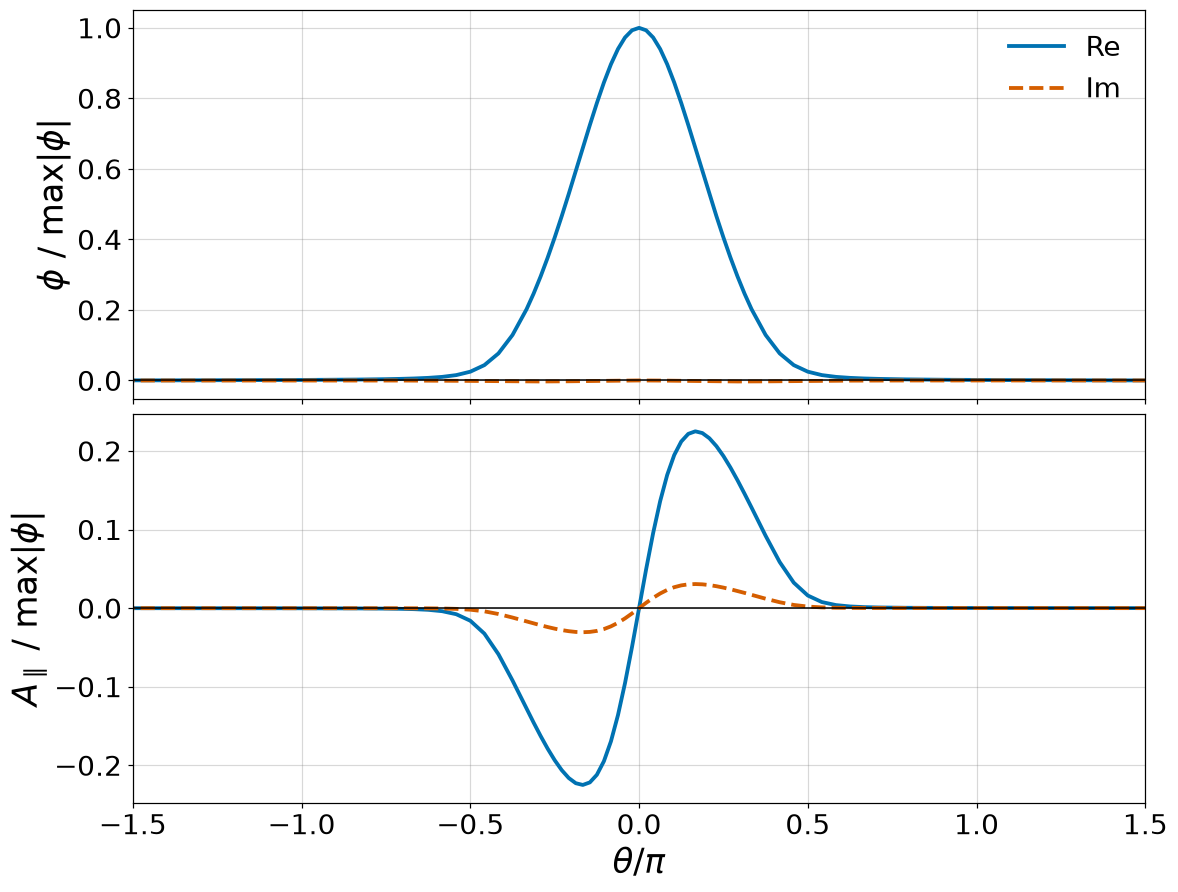

In [2]:
field_labels = {"phi": r"$\phi$", "apar": r"$A_\parallel$"}
fig, axes = plt.subplots(2, 1, figsize=(W, 0.6 * W), sharex=True)
for ax, field in zip(axes, field_labels):
    mode = eigenfunctions.sel(field=field)
    ax.plot(mode.theta / np.pi, mode.real, color="#0072B2", label="Re")
    ax.plot(mode.theta / np.pi, mode.imag, color="#D55E00", ls="--", label="Im")
    ax.axhline(0, color="k", lw=1)
    ax.set(ylabel=rf"{field_labels[field]} / max$|\phi|$", xlim=(-1.5, 1.5))
axes[1].set_xlabel(r"$\theta/\pi$")
axes[0].legend()
fig.savefig(plots_dir / "single_kbm_gs2_eigenfunction.pdf")
plt.show()

## Slide 13 table: the test case's physical parameters

The 8 parameters the `kbm_free` cube varies, for the test case (sample_0818) and for the SPR-045 base deck the cube was built from
(`base_pyro`), both read by pyro in pyro's normalised units. Written to `test_case_parameters.csv` beside the PNG (Fusion_PhD-qp5.32).

In [3]:
import pandas as pd

kbm_free_cube = PyroHypercube(pyroscan_json=Path(os.environ["GK_DATA_ROOT"]).expanduser() / "GS2/Runs/LATIN_HYPERCUBE/SPR-045/kbm_free/pyroscan.json",
                              load_base_pyro=True)
test_pyro, base_pyro = gs2_scan.sample_pyro(0), kbm_free_cube.base_pyro
ion = [name for name in base_pyro.local_species.names if name != "electron"][0]
print("ion species:", ion, "| sample:", gs2_output.sample_name.values)
parameters = {
    r"$k_y\rho$": lambda pyro: pyro.numerics.ky,
    r"$q$": lambda pyro: pyro.local_geometry.q,
    r"$\hat{s}$": lambda pyro: pyro.local_geometry.shat,
    r"$\beta$": lambda pyro: pyro.numerics.beta,
    r"$a/L_{T_i}$": lambda pyro: pyro.local_species[ion].inverse_lt,
    r"$a/L_{T_e}$": lambda pyro: pyro.local_species["electron"].inverse_lt,
    r"$a/L_n$": lambda pyro: pyro.local_species["electron"].inverse_ln,
    r"$\nu_e$": lambda pyro: pyro.local_species["electron"].nu,
}
test_case_parameters = pd.DataFrame([dict(parameter=label, test_case=float(getattr(get(test_pyro), "m", get(test_pyro))),
                                          spr045_base=float(getattr(get(base_pyro), "m", get(base_pyro))),
                                          units=str(getattr(get(test_pyro), "units", "")))
                                     for label, get in parameters.items()])
test_case_parameters.to_csv(plots_dir / "test_case_parameters.csv", index=False, float_format="%.4g")
print(test_case_parameters.to_string(index=False))

ion species: ion1 | sample: sample_0818
  parameter  test_case  spr045_base                        units
  $k_y\rho$   0.019815     0.028149              1 / rhoref_pyro
        $q$   2.590203     3.788293                dimensionless
  $\hat{s}$   4.682714     4.640062                dimensionless
    $\beta$   0.030322     0.055154               beta_ref_ee_B0
$a/L_{T_i}$   6.995418     5.761997        1 / lref_minor_radius
$a/L_{T_e}$   2.603152     2.436740        1 / lref_minor_radius
    $a/L_n$   3.361416     4.981208        1 / lref_minor_radius
    $\nu_e$   0.005973     0.034657 vref_nrl / lref_minor_radius
